# ShapeNet for atom finding in YBCO (Challenge 2)

**Idea:** in HAADF-STEM an atomic column has a known shape: a near-round 2D Gaussian blob with a dark moat around it, about 120 pm wide, sitting on a lattice with a bright and a dim sublattice. Instead of letting a CNN learn arbitrary filters, the first layer here is a small bank of **learnable anisotropic Mexican-hat (difference-of-Gaussians) kernels**. Each kernel has only 4 physical parameters (sigma_x, sigma_y, angle, ring ratio). A tiny dilated-conv head then uses lattice context to output a column heatmap and a bright/dim sublattice class.

**Pipeline**
1. Load the YBCO HAADF frames with their calibrated pixel size.
2. Measure the column shape and lattice from the cleanest frame (1644, 12 pm/px).
3. Resample every frame to a common 24 pm/px, so a column has the same size in pixels at any magnification.
4. Generate synthetic training images from the measured shape and lattice (domain randomization: drift stretch, scan jitter, noise, thickness, no-lattice patches).
5. Train ShapeNet (about 5k parameters) and, as an ablation, the same head with a free 15x15 first layer.
6. Detect columns in every real frame, compare against a classical peak finder, and discuss.


Runtime: about 5 to 10 minutes on a Colab CPU runtime; faster with a GPU.

## 1. Setup and data download
The data folder is the same Google Drive link as in the original `shapeNet_data_.ipynb`. `gdown` creates a folder called `day_25 data/` with `SiSb/` and `YBCO/` inside. If you run this locally next to the `YBCO/` folder, the download is skipped.

In [ ]:
import os, re, json, time
from pathlib import Path

DRIVE_FOLDER = "https://drive.google.com/drive/folders/1h2v6YRPG7cwi7kuMPPPdwV0P0PYu49oH?usp=sharing"

if Path("day_25 data/YBCO").exists():
    DATA_ROOT = Path("day_25 data")
elif Path("YBCO").exists():
    DATA_ROOT = Path(".")
else:
    import subprocess
    subprocess.run(["gdown", "--folder", DRIVE_FOLDER], check=True)
    DATA_ROOT = Path("day_25 data")

YBCO_DIR = DATA_ROOT / "YBCO"
print("YBCO folder:", YBCO_DIR.resolve(), "| files:", len(list(YBCO_DIR.glob("*.emd"))))

YBCO folder: /content/day_25 data/YBCO | files: 18


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage as ndi, optimize
from scipy.spatial import cKDTree
from skimage.feature import peak_local_max
from sklearn.cluster import KMeans
import torch, torch.nn as nn, torch.nn.functional as F

SEED = 0
SMOKE = 0  # set e.g. 20 for a quick test run
np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| device:", DEVICE)
plt.rcParams["figure.dpi"] = 90

torch 2.14.1+cu130 | device: cuda


## 2. Load the YBCO frames with calibrated pixel size
Velox `.emd` files are HDF5. We read the HAADF image and its `PixelSize` from the metadata with `h5py` (preinstalled in Colab), so no extra package is needed. A raw-bytes fallback covers machines without `h5py`.

In [ ]:
def natural_sort_key(path):
    return [int(x) if x.isdigit() else x.lower() for x in re.split(r"(\d+)", Path(path).name)]

def _pixel_size_from_bytes(raw):
    m = re.search(rb'"PixelSize"\s*:\s*\{\s*"width"\s*:\s*"([0-9.eE+-]+)"', raw)
    return float(m.group(1)) * 1e12  # m -> pm

def load_velox(path):
    """Return (image float32, pixel size in pm)."""
    try:
        import h5py
        with h5py.File(path, "r") as f:
            grp = f["Data/Image"]
            fallback = None
            for key in grp:
                d = grp[key]["Data"]
                if d.ndim < 2 or d.shape[0] < 256:
                    continue
                arr = np.asarray(d)
                arr = arr[..., 0] if arr.ndim == 3 else arr
                meta = bytes(np.asarray(grp[key]["Metadata"])[:, 0]).decode("utf-8", "ignore").rstrip("\x00")
                md = json.loads(meta)
                ps = float(md["BinaryResult"]["PixelSize"]["width"]) * 1e12
                det = str(md.get("BinaryResult", {}).get("Detector", ""))
                if "HAADF" in det.upper():
                    return arr.astype(np.float32), ps
                fallback = fallback or (arr.astype(np.float32), ps)
            if fallback is not None:
                return fallback
    except ImportError:
        pass
    # fallback: Velox stores the 2048x2048 uint16 frame uncompressed
    raw = open(path, "rb").read()
    n = 2048; a = np.frombuffer(raw[: len(raw) // 2 * 2], dtype="<u2").astype(np.float64)
    d = np.abs(a[n:] - a[:-n]); c = np.concatenate([[0], np.cumsum(d)])
    L = n * n - n; s = (c[L:] - c[:-L])[: len(a) - n * n + 1]
    ca = np.concatenate([[0], np.cumsum(a)]); m = (ca[n * n:] - ca[:-n * n])[: len(s)] + 1
    off = int(np.argmin(s / m)) * 2
    img = np.frombuffer(raw[off: off + n * n * 2], dtype="<u2").reshape(n, n)
    return img.astype(np.float32), _pixel_size_from_bytes(raw)

files = sorted(YBCO_DIR.glob("*.emd"), key=natural_sort_key)
frames = {}
for fpath in files:
    img, ps = load_velox(fpath)
    frames[fpath.stem.split()[0]] = dict(name=fpath.stem, img=img, ps=ps)
for k, v in frames.items():
    print(f"{k}: {v['img'].shape}, {v['ps']:.1f} pm/px, FOV {v['img'].shape[1]*v['ps']/1000:.1f} nm")

1114: (2048, 2048), 33.7 pm/px, FOV 69.1 nm
1115: (2048, 2048), 33.7 pm/px, FOV 69.1 nm
1117: (2048, 2048), 16.9 pm/px, FOV 34.5 nm
1122: (2048, 2048), 11.9 pm/px, FOV 24.4 nm
1245: (2048, 2048), 16.9 pm/px, FOV 34.5 nm
1333: (2048, 2048), 16.9 pm/px, FOV 34.5 nm
1338: (2048, 2048), 16.9 pm/px, FOV 34.5 nm
1520: (2048, 2048), 23.9 pm/px, FOV 48.9 nm
1530: (2048, 2048), 47.7 pm/px, FOV 97.7 nm
1547: (2048, 2048), 33.7 pm/px, FOV 69.1 nm
1624: (2048, 2048), 33.7 pm/px, FOV 69.1 nm
1643: (2048, 2048), 33.7 pm/px, FOV 69.1 nm
1644: (2048, 2048), 11.9 pm/px, FOV 24.4 nm
1704: (2048, 2048), 33.7 pm/px, FOV 69.1 nm
1709: (2048, 2048), 23.9 pm/px, FOV 48.9 nm
1717: (2048, 2048), 23.9 pm/px, FOV 48.9 nm
1734: (2048, 2048), 33.7 pm/px, FOV 69.1 nm
1739: (2048, 2048), 33.7 pm/px, FOV 69.1 nm


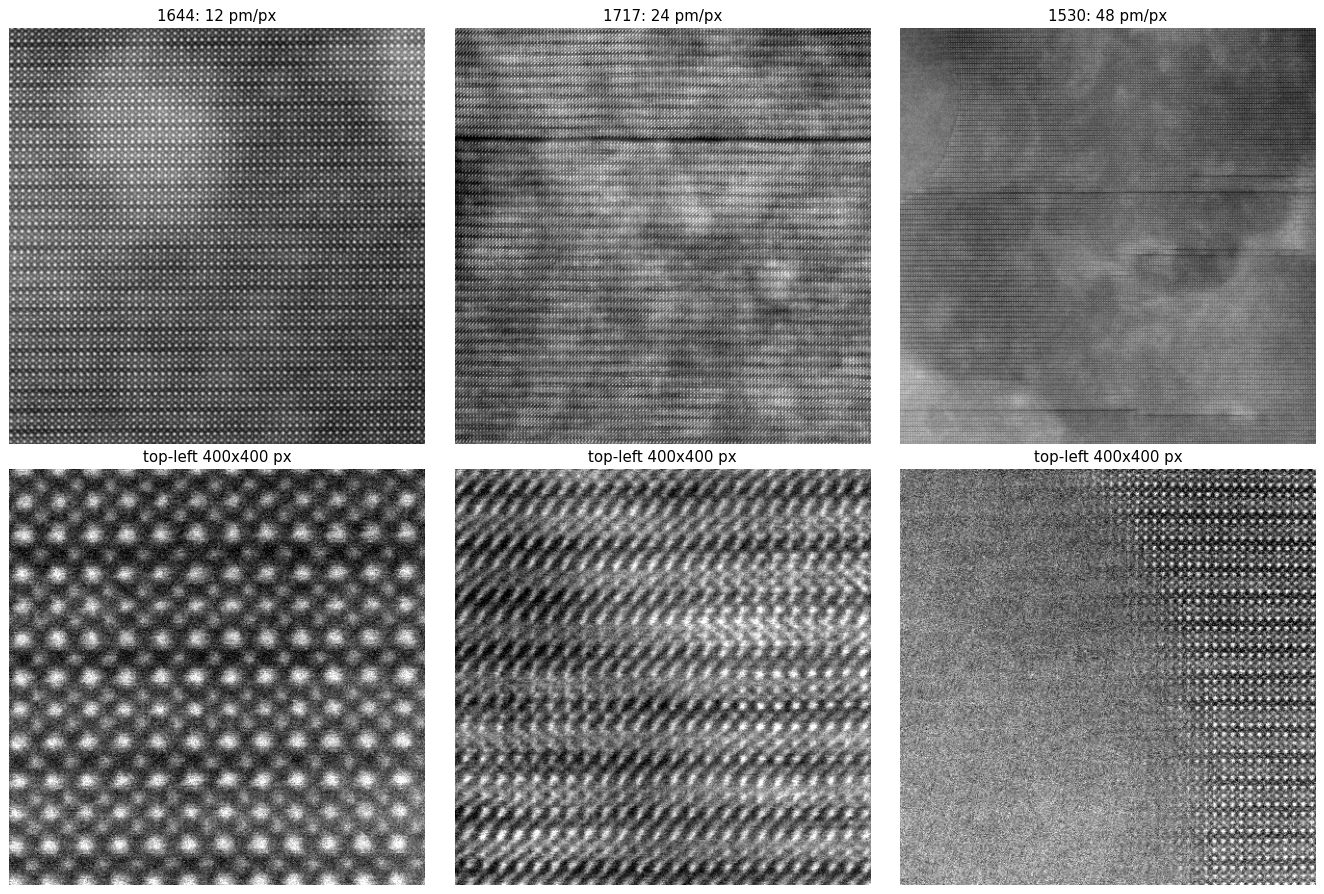

In [ ]:
show = ["1644", "1717", "1530"]
fig, ax = plt.subplots(2, 3, figsize=(15, 10))
for j, k in enumerate(show):
    im = frames[k]["img"]; lo, hi = np.percentile(im, [0.5, 99.5])
    ax[0, j].imshow(im, cmap="gray", vmin=lo, vmax=hi); ax[0, j].set_title(f"{k}: {frames[k]['ps']:.0f} pm/px")
    c = im[:400, :400]; lo, hi = np.percentile(c, [0.5, 99.5])
    ax[1, j].imshow(c, cmap="gray", vmin=lo, vmax=hi); ax[1, j].set_title("top-left 400x400 px")
for a in ax.flat: a.axis("off")
plt.tight_layout(); plt.show()

## 3. Resample to a common physical scale
The column has a fixed physical width (about 120 pm) but a pixel width that changes with magnification. Resampling every frame to `TARGET_PM = 24 pm/px` gives one fixed object size for the network. The background (thickness, slow contrast changes) is removed with a wide Gaussian and the image is normalized to unit robust spread.

In [ ]:
TARGET_PM = 24.0

def preprocess(img, ps, target=TARGET_PM):
    z = ps / target
    im = ndi.zoom(img.astype(np.float32), z, order=1) if abs(z - 1) > 1e-3 else img.astype(np.float32)
    im = im - ndi.gaussian_filter(im, 25)
    mad = np.median(np.abs(im - np.median(im))) * 1.4826 + 1e-6
    return (im / mad).astype(np.float32), z

for k, v in frames.items():
    v["pre"], v["zoom"] = preprocess(v["img"], v["ps"])
print({k: v["pre"].shape for k, v in frames.items()})

{'1114': (2879, 2879), '1115': (2879, 2879), '1117': (1439, 1439), '1122': (1018, 1018), '1245': (1439, 1439), '1333': (1439, 1439), '1338': (1439, 1439), '1520': (2036, 2036), '1530': (4071, 4071), '1547': (2879, 2879), '1624': (2879, 2879), '1643': (2879, 2879), '1644': (1018, 1018), '1704': (2879, 2879), '1709': (2036, 2036), '1717': (2036, 2036), '1734': (2879, 2879), '1739': (2879, 2879)}


## 4. Measure the shape: column profile, sublattices, lattice
On the cleanest frame (1644) a classical finder (Gaussian smoothing + local maxima) gives reliable bright columns. Averaging a patch around every detected column gives the empirical column shape, which we fit with a rotated 2D Gaussian. Peak intensities split into a bright and a dim class (Z-contrast). Nearest-neighbour vectors give the lattice spacing and orientation.

5559 columns in 1644
column sigma: 1.97 x 2.08 px at 24.0 pm/px  ->  FWHM 111 x 117 pm
lattice vectors (bright sublattice): 17.0 x 16.0 px = 0.408 x 0.385 nm, rotation 0.0 deg
nearest neighbour over all columns: 0.274 nm (half cell diagonal = 0.280 nm -> dim columns sit at the cell centre)
dim / bright peak intensity ratio: 0.29


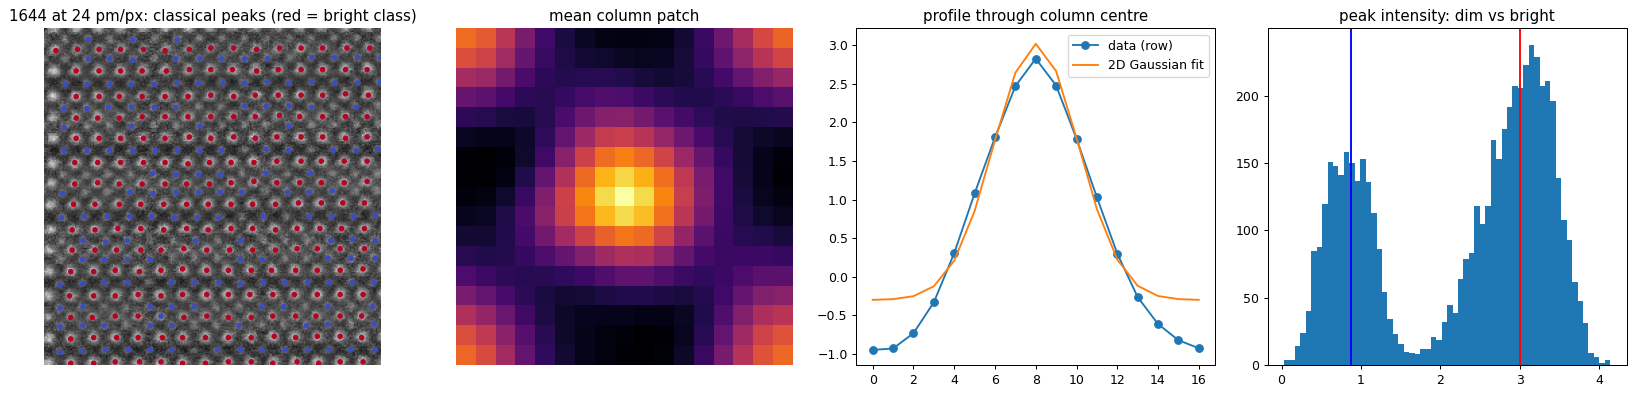

In [ ]:
def classical_finder(pre, min_distance=5, q=60, smooth=1.0):
    s = ndi.gaussian_filter(pre, smooth)
    return peak_local_max(s, min_distance=min_distance, threshold_abs=np.percentile(s, q), exclude_border=8)

def gauss2d(p, y, x):
    A, y0, x0, sy, sx, th, b = p
    c, s = np.cos(th), np.sin(th)
    yr = (y - y0) * c - (x - x0) * s; xr = (y - y0) * s + (x - x0) * c
    return A * np.exp(-yr**2 / (2 * sy**2) - xr**2 / (2 * sx**2)) + b

def fit_gauss(P):
    h = P.shape[0] // 2; y, x = np.mgrid[: P.shape[0], : P.shape[1]]
    r = optimize.least_squares(lambda p: (gauss2d(p, y, x) - P).ravel(), [P.max() - P.min(), h, h, 2, 2, 0, P.min()])
    return r.x

REF = "1644"
pre = frames[REF]["pre"]
pk = classical_finder(pre)
H = 8
P = np.stack([pre[y - H: y + H + 1, x - H: x + H + 1] for y, x in pk])
fit = fit_gauss(P.mean(0))
SIG_Y, SIG_X = abs(fit[3]), abs(fit[4])
SIGMA_COL = float(np.sqrt(SIG_X * SIG_Y))

amp = ndi.gaussian_filter(pre, 1.0)[pk[:, 0], pk[:, 1]]
km = KMeans(2, n_init=10, random_state=SEED).fit(amp[:, None])
c_lo, c_hi = sorted(km.cluster_centers_[:, 0])
DIM_RATIO = float(c_lo / c_hi)

pk_b = pk[km.labels_ == np.argmax(km.cluster_centers_[:, 0])]   # bright sublattice only
dd, ii = cKDTree(pk_b).query(pk_b, k=7)
vec = (pk_b[ii[:, 1:]] - pk_b[:, None, :]).reshape(-1, 2).astype(float)
vec[vec[:, 1] < 0] *= -1                                          # fold +v / -v together
ang = np.degrees(np.arctan2(vec[:, 0], vec[:, 1])); L = np.hypot(*vec.T)
near0 = (np.abs(ang) < 20) & (L < 30); near90 = (np.abs(np.abs(ang) - 90) < 20) & (L < 30)
A_X, A_Y = float(np.median(L[near0])), float(np.median(L[near90]))   # lattice vectors along rows / columns
LAT_ANGLE = float(np.median(ang[near0]))
A_LAT = 0.5 * (A_X + A_Y)
print(f"{len(pk)} columns in {REF}")
print(f"column sigma: {SIG_Y:.2f} x {SIG_X:.2f} px at {TARGET_PM} pm/px  ->  FWHM {2.355*SIG_Y*TARGET_PM:.0f} x {2.355*SIG_X*TARGET_PM:.0f} pm")
d_all = cKDTree(pk).query(pk, k=2)[0][:, 1]
print(f"lattice vectors (bright sublattice): {A_X:.1f} x {A_Y:.1f} px = {A_X*TARGET_PM/1000:.3f} x {A_Y*TARGET_PM/1000:.3f} nm, rotation {LAT_ANGLE:.1f} deg")
print(f"nearest neighbour over all columns: {np.median(d_all)*TARGET_PM/1000:.3f} nm (half cell diagonal = {np.hypot(A_X, A_Y)/2*TARGET_PM/1000:.3f} nm -> dim columns sit at the cell centre)")
print(f"dim / bright peak intensity ratio: {DIM_RATIO:.2f}")

fig, ax = plt.subplots(1, 4, figsize=(18, 4.5))
c = pre[:250, :250]; m = (pk[:, 0] < 250) & (pk[:, 1] < 250)
ax[0].imshow(c, cmap="gray"); ax[0].scatter(pk[m, 1], pk[m, 0], c=km.labels_[m] == np.argmax(km.cluster_centers_[:, 0]), cmap="coolwarm", s=12)
ax[0].set_title(f"{REF} at {TARGET_PM:.0f} pm/px: classical peaks (red = bright class)"); ax[0].axis("off")
ax[1].imshow(P.mean(0), cmap="inferno"); ax[1].set_title("mean column patch"); ax[1].axis("off")
ax[2].plot(P.mean(0)[H], "o-", label="data (row)"); y, x = np.mgrid[:2*H+1, :2*H+1]
ax[2].plot(gauss2d(fit, y, x)[H], "-", label="2D Gaussian fit"); ax[2].legend(); ax[2].set_title("profile through column centre")
ax[3].hist(amp, 60); ax[3].axvline(c_lo, c="b"); ax[3].axvline(c_hi, c="r"); ax[3].set_title("peak intensity: dim vs bright")
plt.tight_layout(); plt.show()

## 5. Synthetic training data from the measured shape
Each synthetic image is rendered from the measured physics, with randomization around it:
- bright lattice with spacing and orientation near the measured values, optional dim sublattice at the cell centre (intensity ratio near the measured one);
- columns as anisotropic Gaussians (random stretch and angle, imitating drift and shear as in frame 1717);
- row-wise scan jitter (shifts columns and labels together), Poisson + Gaussian noise, slow thickness modulation;
- sometimes a no-lattice patch (amorphous or damaged area) with **no** labels, so the network learns not to fire on noise.

Targets: a column heatmap (Gaussian, sigma 1.2 px, peak 1) and a dim-sublattice mask.

synthetic train (1500, 1, 128, 128), val (200, 1, 128, 128) in 107.7s


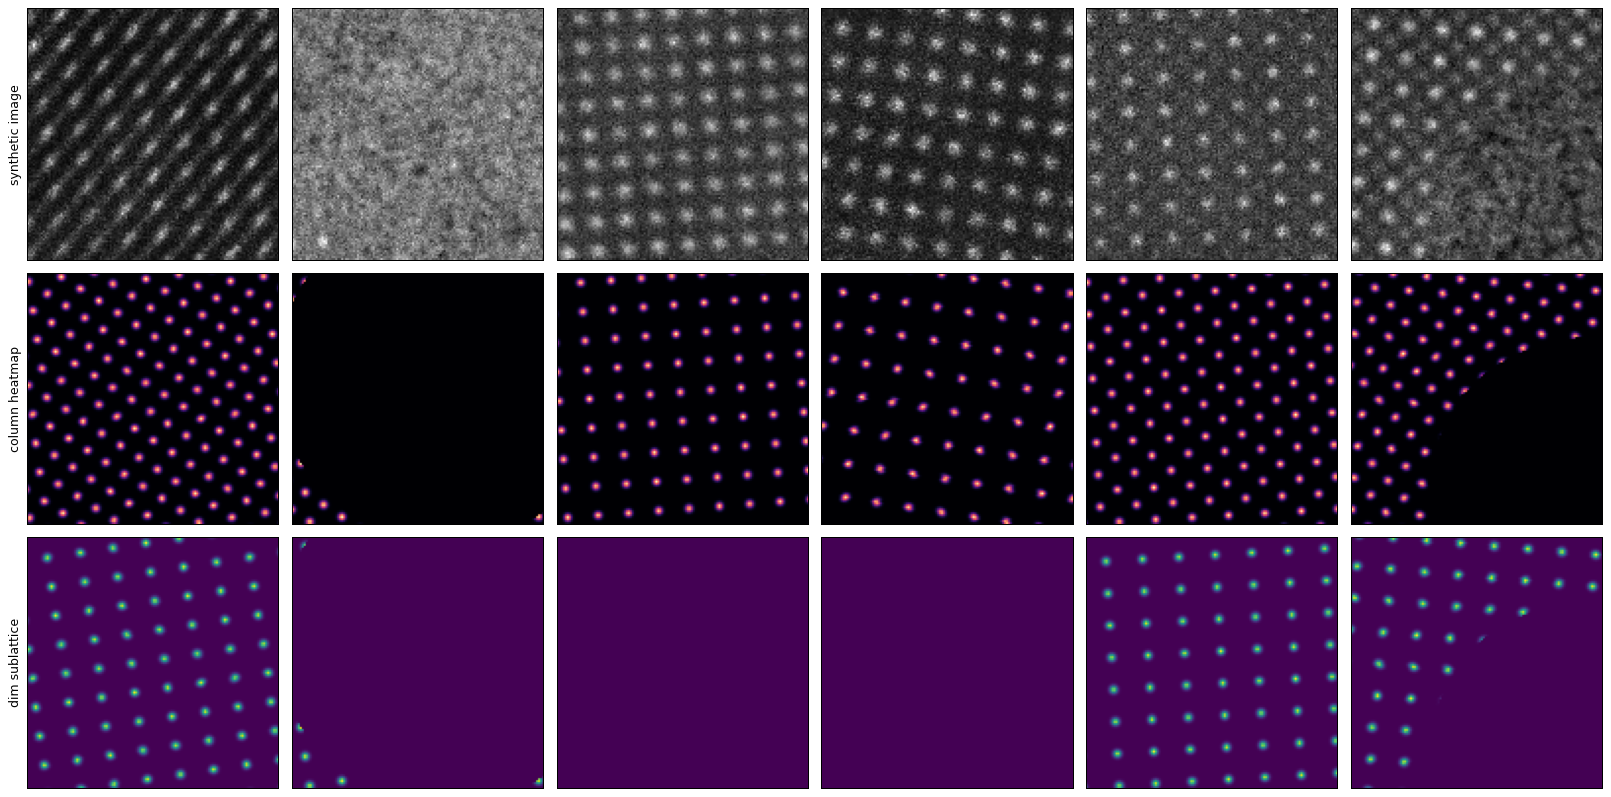

In [ ]:
def aniso_kernel(sy, sx, th, size=15):
    h = size // 2; y, x = np.mgrid[-h:h + 1, -h:h + 1].astype(float)
    c, s = np.cos(th), np.sin(th)
    yr = y * c - x * s; xr = y * s + x * c
    k = np.exp(-yr**2 / (2 * sy**2) - xr**2 / (2 * sx**2))
    return k / k.max()

def splat(shape, pts, w=None):
    out = np.zeros(shape, np.float32)
    if len(pts) == 0: return out
    y, x = pts[:, 0], pts[:, 1]; y0, x0 = np.floor(y).astype(int), np.floor(x).astype(int)
    fy, fx = y - y0, x - x0; w = np.ones(len(pts)) if w is None else w
    for dy, dx, ww in [(0, 0, (1 - fy) * (1 - fx)), (1, 0, fy * (1 - fx)), (0, 1, (1 - fy) * fx), (1, 1, fy * fx)]:
        yy, xx = y0 + dy, x0 + dx; ok = (yy >= 0) & (yy < shape[0]) & (xx >= 0) & (xx < shape[1])
        np.add.at(out, (yy[ok], xx[ok]), (w * ww)[ok])
    return out

def row_shift(img, shifts):
    xs = np.arange(img.shape[1], dtype=float)
    return np.stack([np.interp(xs - s, xs, r) for r, s in zip(img, shifts)])

def make_sample(S=128, rng=np.random):
    pad = 24; N = S + 2 * pad
    f = rng.uniform(0.85, 1.15); a, b = A_X * f * rng.uniform(0.95, 1.05), A_Y * f * rng.uniform(0.95, 1.05)
    if rng.rand() < 0.3: a, b = b, a
    th = np.radians(LAT_ANGLE + rng.uniform(-12, 12))
    a1 = a * np.array([np.sin(th), np.cos(th)]); a2 = b * np.array([np.cos(th), -np.sin(th)])
    n = int(N / min(a, b)) + 3; i, j = np.meshgrid(np.arange(-n, n + 1), np.arange(-n, n + 1))
    off = rng.uniform(0, 1, 2) * a
    bright = i.ravel()[:, None] * a1 + j.ravel()[:, None] * a2 + off
    has_dim = rng.rand() < 0.7
    dim = bright + 0.5 * (a1 + a2) if has_dim else np.zeros((0, 2))
    keep = lambda p: p[(p[:, 0] > -8) & (p[:, 0] < N + 8) & (p[:, 1] > -8) & (p[:, 1] < N + 8)]
    bright, dim = keep(bright), keep(dim)
    ratio = np.clip(DIM_RATIO * rng.uniform(0.6, 1.3), 0.15, 0.95)
    sig = SIGMA_COL * rng.uniform(0.8, 1.25); stretch = rng.uniform(1.0, 2.0) if rng.rand() < 0.5 else 1.0
    k = aniso_kernel(sig * stretch, sig / np.sqrt(stretch), rng.uniform(0, np.pi), size=int(8 * sig * stretch) | 1)
    amp_b = rng.uniform(0.8, 1.2, len(bright)); amp_d = ratio * rng.uniform(0.8, 1.2, len(dim))
    img = ndi.convolve(splat((N, N), bright, amp_b) + splat((N, N), dim, amp_d), k, mode="constant")
    heat = np.clip(ndi.gaussian_filter(splat((N, N), np.vstack([bright, dim])), 1.2) * 2 * np.pi * 1.2**2, 0, 1)
    dmask = np.clip(ndi.gaussian_filter(splat((N, N), dim), 1.2) * 2 * np.pi * 1.2**2, 0, 1)
    if rng.rand() < 0.25:  # no-lattice patch: remove signal and labels
        yy, xx = np.mgrid[:N, :N]; cy, cx = rng.uniform(0, N, 2); r = rng.uniform(0.2, 0.6) * N
        blob = ndi.gaussian_filter((np.hypot(yy - cy, xx - cx) < r).astype(float), 6)
        img = img * (1 - blob) + blob * ndi.gaussian_filter(rng.randn(N, N), 1.5) * 0.6
        heat = heat * (blob < 0.5); dmask = dmask * (blob < 0.5)
    if rng.rand() < 0.7:  # scan jitter
        sh = np.cumsum(rng.randn(N)) * rng.uniform(0.05, 0.4); sh -= sh.mean()
        img, heat, dmask = row_shift(img, sh), row_shift(heat, sh), row_shift(dmask, sh)
    img = img * (1 + 0.4 * ndi.gaussian_filter(rng.randn(N, N), 30) * 10) + 0.3 * ndi.gaussian_filter(rng.randn(N, N), 20) * 10
    dose = rng.uniform(5, 60)
    img = rng.poisson(np.clip(img - img.min(), 0, None) * dose) / dose + rng.randn(N, N) * rng.uniform(0.02, 0.15)
    img = img - ndi.gaussian_filter(img, 25)
    img = img / (np.median(np.abs(img - np.median(img))) * 1.4826 + 1e-6)
    sl = slice(pad, pad + S)
    return img[sl, sl].astype(np.float32), heat[sl, sl].astype(np.float32), dmask[sl, sl].astype(np.float32)

def make_set(n, S=128, seed=0):
    rng = np.random.RandomState(seed)
    X, Y, D = zip(*[make_sample(S, rng) for _ in range(n)])
    return np.stack(X)[:, None], np.stack(Y)[:, None], np.stack(D)[:, None]

t0 = time.time()
Xtr, Ytr, Dtr = make_set(SMOKE or 1500, seed=1)
Xva, Yva, Dva = make_set(SMOKE or 200, seed=2)
print(f"synthetic train {Xtr.shape}, val {Xva.shape} in {time.time()-t0:.1f}s")

fig, ax = plt.subplots(3, 6, figsize=(18, 9))
for j in range(6):
    ax[0, j].imshow(Xtr[j, 0], cmap="gray"); ax[1, j].imshow(Ytr[j, 0], cmap="magma"); ax[2, j].imshow(Dtr[j, 0], cmap="viridis")
for a, t in zip(ax[:, 0], ["synthetic image", "column heatmap", "dim sublattice"]): a.set_ylabel(t)
for a in ax.flat: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

## 6. The network: a learnable column-shape layer + tiny lattice-context head
**`ColumnShapeLayer`**: K kernels, each a rotated anisotropic Mexican hat `G(sx, sy, theta) - G(r*sx, r*sy, theta)` (zero mean, unit norm). It has only 4 learnable numbers per kernel, initialized at the measured column width, at different angles. This is the "looking for the shape" part, and after training we can read off what shape it settled on.

**Head**: the K shape responses plus the image go through three 3x3 convolutions with dilation 1, 2, 4 (receptive field about 30 px, about two lattice spacings, enough to see the neighbours and the motif), then a 1x1 conv to two maps: column heatmap and dim-sublattice logit.

**Ablation (`FreeCNN`)**: identical head, but the first layer is K unconstrained 15x15 filters.

In [ ]:
class ColumnShapeLayer(nn.Module):
    def __init__(self, K=4, size=15, sigma0=2.0):
        super().__init__()
        self.size = size
        self.log_sx = nn.Parameter(torch.full((K,), float(np.log(sigma0))))
        self.log_sy = nn.Parameter(torch.full((K,), float(np.log(sigma0))) + torch.linspace(-0.2, 0.2, K))
        self.theta = nn.Parameter(torch.linspace(0, np.pi, K + 1)[:-1].clone())
        self.log_r = nn.Parameter(torch.full((K,), float(np.log(1.8))))
        h = size // 2
        yy, xx = torch.meshgrid(torch.arange(-h, h + 1.0), torch.arange(-h, h + 1.0), indexing="ij")
        self.register_buffer("yy", yy); self.register_buffer("xx", xx)

    def kernels(self):
        sx, sy = self.log_sx.exp()[:, None, None], self.log_sy.exp()[:, None, None]
        r = 1.0 + F.softplus(self.log_r)[:, None, None]
        c, s = torch.cos(self.theta)[:, None, None], torch.sin(self.theta)[:, None, None]
        xr = self.xx * c + self.yy * s; yr = -self.xx * s + self.yy * c
        g1 = torch.exp(-(xr**2 / (2 * sx**2) + yr**2 / (2 * sy**2)))
        g2 = torch.exp(-(xr**2 / (2 * (r * sx)**2) + yr**2 / (2 * (r * sy)**2)))
        k = g1 / g1.sum((1, 2), keepdim=True) - g2 / g2.sum((1, 2), keepdim=True)
        return (k / k.flatten(1).norm(dim=1)[:, None, None])[:, None]

    def forward(self, x):
        return F.conv2d(x, self.kernels(), padding=self.size // 2)

class Head(nn.Module):
    def __init__(self, cin, w=16):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(cin, w, 3, padding=1), nn.ReLU(),
            nn.Conv2d(w, w, 3, padding=2, dilation=2), nn.ReLU(),
            nn.Conv2d(w, w, 3, padding=4, dilation=4), nn.ReLU(),
            nn.Conv2d(w, 2, 1))
    def forward(self, x): return self.net(x)

class ShapeNet(nn.Module):
    def __init__(self, K=4, sigma0=2.0):
        super().__init__(); self.shape = ColumnShapeLayer(K, sigma0=sigma0); self.head = Head(K + 1)
    def forward(self, x): return self.head(torch.cat([self.shape(x), x], 1))

class FreeCNN(nn.Module):
    def __init__(self, K=4):
        super().__init__(); self.first = nn.Conv2d(1, K, 15, padding=7); self.head = Head(K + 1)
    def forward(self, x): return self.head(torch.cat([self.first(x), x], 1))

nparams = lambda m: sum(p.numel() for p in m.parameters())
print("ShapeNet params:", nparams(ShapeNet()), "| shape layer:", nparams(ColumnShapeLayer()))
print("FreeCNN params:", nparams(FreeCNN()))

ShapeNet params: 5426 | shape layer: 16
FreeCNN params: 6314


## 7. Train both networks on the synthetic data

ShapeNet
  step     0  loss 1.0922  (2s)
  step   300  loss 0.2711  (7s)
  step   600  loss 0.2558  (12s)
  step   900  loss 0.2478  (17s)
  step  1199  loss 0.2477  (22s)
FreeCNN
  step     0  loss 1.1741  (0s)
  step   300  loss 0.2641  (5s)
  step   600  loss 0.2552  (9s)
  step   900  loss 0.2467  (14s)
  step  1199  loss 0.2466  (19s)


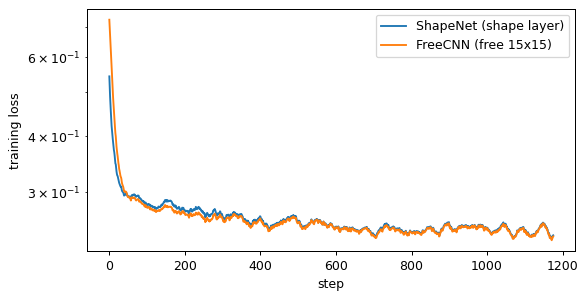

In [ ]:
def loss_fn(out, y, d):
    lh = F.binary_cross_entropy_with_logits(out[:, :1], y, pos_weight=torch.tensor(4.0, device=y.device))
    m = (y > 0.5).float()
    lc = (F.binary_cross_entropy_with_logits(out[:, 1:], (d > 0.5).float(), reduction="none") * m).sum() / (m.sum() + 1)
    return lh + 0.5 * lc

def train(model, steps=1200, bs=16, lr=3e-3, seed=0):
    torch.manual_seed(seed); model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    Xt, Yt, Dt = (torch.from_numpy(a) for a in (Xtr, Ytr, Dtr))
    hist = []; t0 = time.time()
    for it in range(steps):
        idx = torch.randint(0, len(Xt), (bs,))
        x, y, d = Xt[idx], Yt[idx], Dt[idx]
        if it % 2: x, y, d = x.flip(-1), y.flip(-1), d.flip(-1)
        x, y, d = x.to(DEVICE), y.to(DEVICE), d.to(DEVICE)
        loss = loss_fn(model(x), y, d)
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        hist.append(loss.item())
        if it % 300 == 0 or it == steps - 1:
            print(f"  step {it:5d}  loss {np.mean(hist[-50:]):.4f}  ({time.time()-t0:.0f}s)")
    return model.eval(), hist

print("ShapeNet"); shapenet, h_shape = train(ShapeNet(sigma0=SIGMA_COL))
print("FreeCNN");  freecnn, h_free = train(FreeCNN())

plt.figure(figsize=(7, 3.5))
sm = lambda h: np.convolve(h, np.ones(25) / 25, mode="valid")
plt.plot(sm(h_shape), label="ShapeNet (shape layer)"); plt.plot(sm(h_free), label="FreeCNN (free 15x15)")
plt.yscale("log"); plt.xlabel("step"); plt.ylabel("training loss"); plt.legend(); plt.show()

## 8. What shape did the network learn?
Because the first layer is parametric, we can read the learned shapes directly and compare them with the measured column. The free CNN's first-layer filters are shown for contrast.

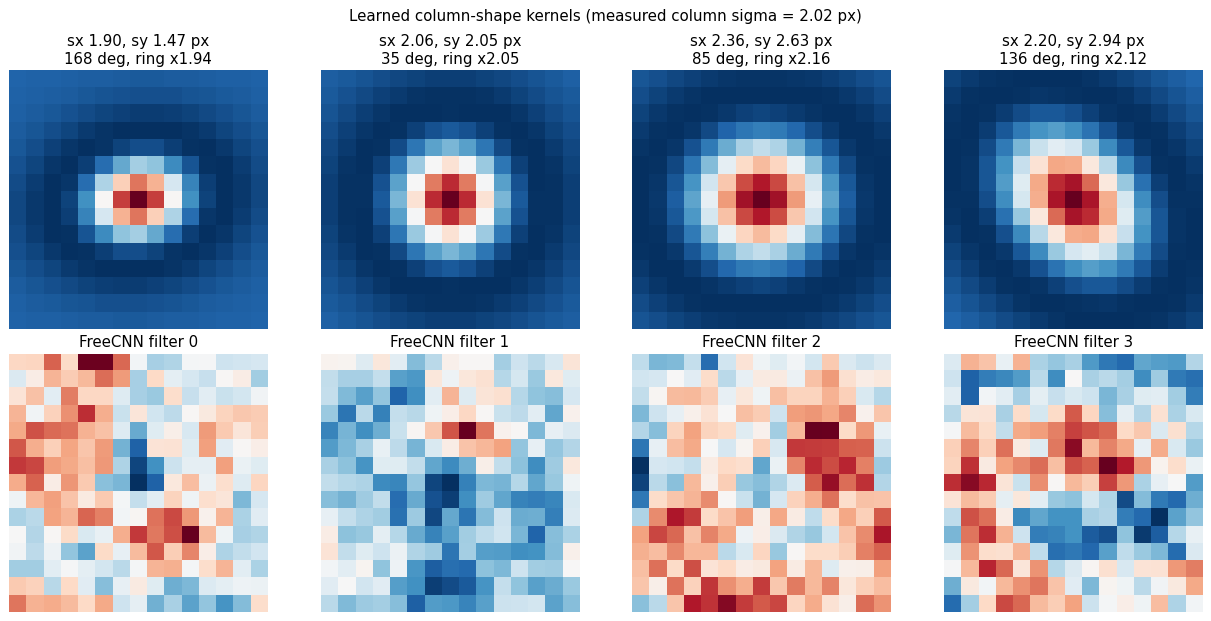

kernel 0: FWHM 107 x 83 pm, angle 168 deg, anisotropy 1.29
kernel 1: FWHM 117 x 116 pm, angle 35 deg, anisotropy 1.01
kernel 2: FWHM 134 x 149 pm, angle 85 deg, anisotropy 1.11
kernel 3: FWHM 125 x 166 pm, angle 136 deg, anisotropy 1.33


In [ ]:
with torch.no_grad():
    K_shape = shapenet.shape.kernels().cpu().numpy()[:, 0]
    sx = shapenet.shape.log_sx.exp().cpu().numpy(); sy = shapenet.shape.log_sy.exp().cpu().numpy()
    thd = np.degrees(shapenet.shape.theta.cpu().numpy()) % 180
    rr = 1 + F.softplus(shapenet.shape.log_r).cpu().numpy()
    K_free = freecnn.first.weight.cpu().numpy()[:, 0]
fig, ax = plt.subplots(2, 4, figsize=(14, 7))
for k in range(4):
    ax[0, k].imshow(K_shape[k], cmap="RdBu_r"); ax[0, k].set_title(f"sx {sx[k]:.2f}, sy {sy[k]:.2f} px\n{thd[k]:.0f} deg, ring x{rr[k]:.2f}")
    ax[1, k].imshow(K_free[k], cmap="RdBu_r"); ax[1, k].set_title(f"FreeCNN filter {k}")
for a in ax.flat: a.axis("off")
plt.suptitle(f"Learned column-shape kernels (measured column sigma = {SIGMA_COL:.2f} px)"); plt.tight_layout(); plt.show()
for k in range(4):
    print(f"kernel {k}: FWHM {2.355*sx[k]*TARGET_PM:.0f} x {2.355*sy[k]*TARGET_PM:.0f} pm, angle {thd[k]:.0f} deg, anisotropy {max(sx[k],sy[k])/min(sx[k],sy[k]):.2f}")

## 9. Detection: heatmap -> coordinates, and synthetic validation
Columns are local maxima of the heatmap above 0.4; the class map at each peak decides bright vs dim. On the synthetic validation set we know the truth, so we report precision, recall and F1 (a match is within 3 px = 72 pm) for ShapeNet, FreeCNN and the classical finder.

In [ ]:
@torch.no_grad()
def predict(model, pre, tile=512, ov=32):
    Hh, Ww = pre.shape; heat = np.zeros((Hh, Ww), np.float32); cls = np.zeros((Hh, Ww), np.float32)
    for y0 in range(0, Hh, tile - 2 * ov):
        for x0 in range(0, Ww, tile - 2 * ov):
            ya, xa = max(y0 - ov, 0), max(x0 - ov, 0); yb, xb = min(y0 + tile - ov, Hh), min(x0 + tile - ov, Ww)
            out = torch.sigmoid(model(torch.from_numpy(pre[ya:yb, xa:xb][None, None]).to(DEVICE))).cpu().numpy()[0]
            sy_, sx_ = slice(y0 - ya, min(yb, y0 + tile - 2 * ov) - ya), slice(x0 - xa, min(xb, x0 + tile - 2 * ov) - xa)
            heat[y0: y0 + (sy_.stop - sy_.start), x0: x0 + (sx_.stop - sx_.start)] = out[0][sy_, sx_]
            cls[y0: y0 + (sy_.stop - sy_.start), x0: x0 + (sx_.stop - sx_.start)] = out[1][sy_, sx_]
    return heat, cls

def detect(heat, cls, thr=0.4, md=4):
    pk = peak_local_max(heat, min_distance=md, threshold_abs=thr, exclude_border=4)
    return pk, cls[pk[:, 0], pk[:, 1]] > 0.5

def match(pred, gt, r=3.0):
    if len(pred) == 0 or len(gt) == 0: return 0, len(pred), len(gt)
    d, _ = cKDTree(gt).query(pred); tp = int(np.sum(d <= r))
    d2, _ = cKDTree(pred).query(gt); tp2 = int(np.sum(d2 <= r))
    return min(tp, tp2), len(pred) - tp, len(gt) - tp2

def prf(tp, fp, fn):
    p = tp / max(tp + fp, 1); r = tp / max(tp + fn, 1); return p, r, 2 * p * r / max(p + r, 1e-9)

tot = {k: np.zeros(3) for k in ["ShapeNet", "FreeCNN", "Classical"]}
for i in range(len(Xva)):
    gt = peak_local_max(Yva[i, 0], min_distance=3, threshold_abs=0.5, exclude_border=4)
    for name, m in [("ShapeNet", shapenet), ("FreeCNN", freecnn)]:
        h, c = predict(m, Xva[i, 0]); tot[name] += match(detect(h, c)[0], gt)
    tot["Classical"] += match(classical_finder(Xva[i, 0], min_distance=4, q=70), gt)
print("synthetic validation (200 images):")
for k, v in tot.items():
    p, r, f = prf(*v); print(f"  {k:9s}  precision {p:.3f}  recall {r:.3f}  F1 {f:.3f}")

synthetic validation (200 images):
  ShapeNet   precision 0.946  recall 0.987  F1 0.966
  FreeCNN    precision 0.947  recall 0.991  F1 0.968
  Classical  precision 0.848  recall 0.756  F1 0.799


## 10. Real frames: detections overlaid on the original image
Coordinates are mapped back to original pixels (divide by the resampling factor). Red = bright sublattice, cyan = dim sublattice.

1114: ShapeNet  58370 columns (50.4% dim) | FreeCNN  58411 | classical  41376
1115: ShapeNet  56518 columns (50.1% dim) | FreeCNN  57065 | classical  41651
1117: ShapeNet  14602 columns (50.0% dim) | FreeCNN  14602 | classical  11835
1122: ShapeNet   7275 columns (50.7% dim) | FreeCNN   7206 | classical   5225
1245: ShapeNet  14348 columns (49.9% dim) | FreeCNN  14330 | classical   9705
1333: ShapeNet  13057 columns (49.0% dim) | FreeCNN  12758 | classical   8287
1338: ShapeNet  12999 columns (49.1% dim) | FreeCNN  12462 | classical   7918
1520: ShapeNet  25238 columns (47.5% dim) | FreeCNN  24947 | classical  15968
1530: ShapeNet 111280 columns (50.2% dim) | FreeCNN 111364 | classical  84971
1547: ShapeNet  56428 columns (49.7% dim) | FreeCNN  56686 | classical  35547
1624: ShapeNet  57499 columns (48.7% dim) | FreeCNN  56882 | classical  33739
1643: ShapeNet  58702 columns (49.9% dim) | FreeCNN  58611 | classical  40581
1644: ShapeNet   7434 columns (49.8% dim) | FreeCNN   7386 | cla

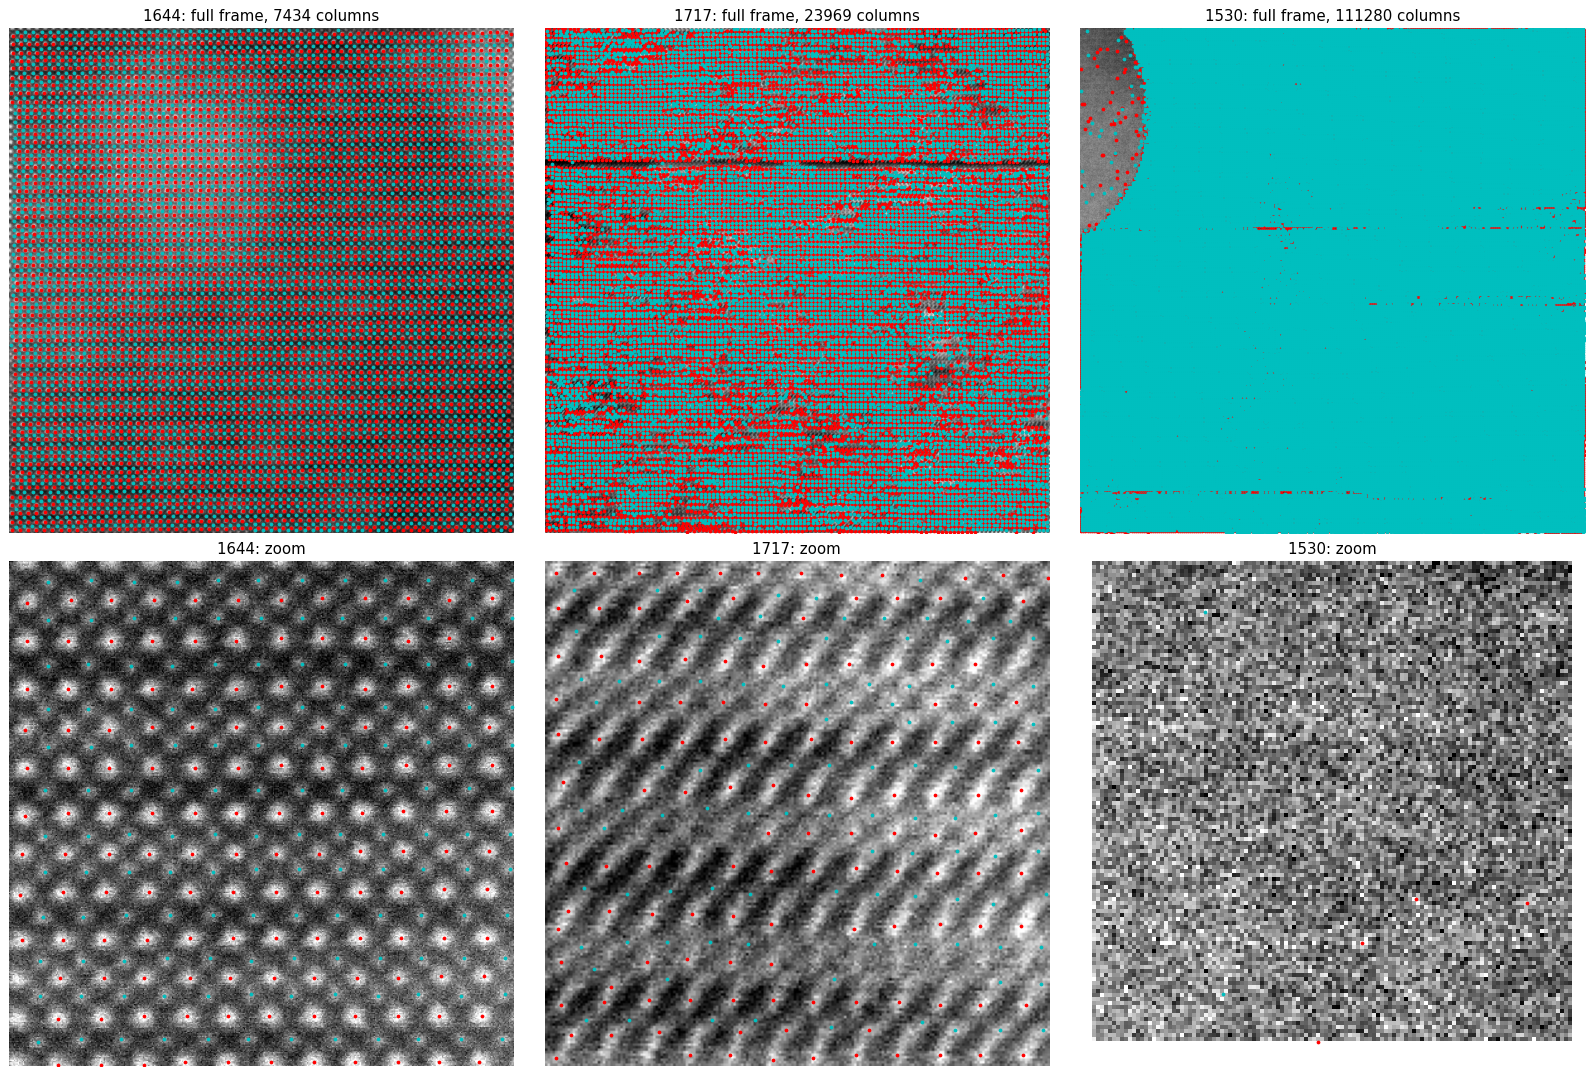

In [ ]:
results = {}
for k, v in frames.items():
    h, c = predict(shapenet, v["pre"]); pk_, dim_ = detect(h, c)
    hf, cf = predict(freecnn, v["pre"]); pkf, _ = detect(hf, cf)
    pkc = classical_finder(v["pre"])
    results[k] = dict(heat=h, pk=pk_, dim=dim_, pk_free=pkf, pk_cls=pkc)
    print(f"{k}: ShapeNet {len(pk_):6d} columns ({dim_.mean()*100:4.1f}% dim) | FreeCNN {len(pkf):6d} | classical {len(pkc):6d}")

def overlay(k, box=None, ax=None, title=""):
    v, r = frames[k], results[k]; z = v["zoom"]
    im = v["img"]; box = box or (0, 0, im.shape[0], im.shape[1]); y0, x0, y1, x1 = box
    crop = im[y0:y1, x0:x1]; lo, hi = np.percentile(crop, [0.5, 99.5])
    ax.imshow(crop, cmap="gray", vmin=lo, vmax=hi)
    pts = r["pk"] / z; m = (pts[:, 0] >= y0) & (pts[:, 0] < y1) & (pts[:, 1] >= x0) & (pts[:, 1] < x1)
    for sel, col in [(~r["dim"], "r"), (r["dim"], "c")]:
        mm = m & sel; ax.scatter(pts[mm, 1] - x0, pts[mm, 0] - y0, s=9, c=col, linewidths=0)
    ax.set_title(title or f"{k} ({v['ps']:.0f} pm/px)"); ax.axis("off")

fig, ax = plt.subplots(2, 3, figsize=(18, 12))
for j, k in enumerate(["1644", "1717", "1530"]):
    overlay(k, ax=ax[0, j], title=f"{k}: full frame, {len(results[k]['pk'])} columns")
    s = int(400 * 12 / frames[k]["ps"]) if k != "1644" else 400
    overlay(k, box=(0, 0, max(s, 120), max(s, 120)), ax=ax[1, j], title=f"{k}: zoom")
plt.tight_layout(); plt.show()

### Heatmaps and a side-by-side on the hardest frames
1530 contains an area without a resolved lattice; 1717 has strong drift stretch. Compare where each method fires.

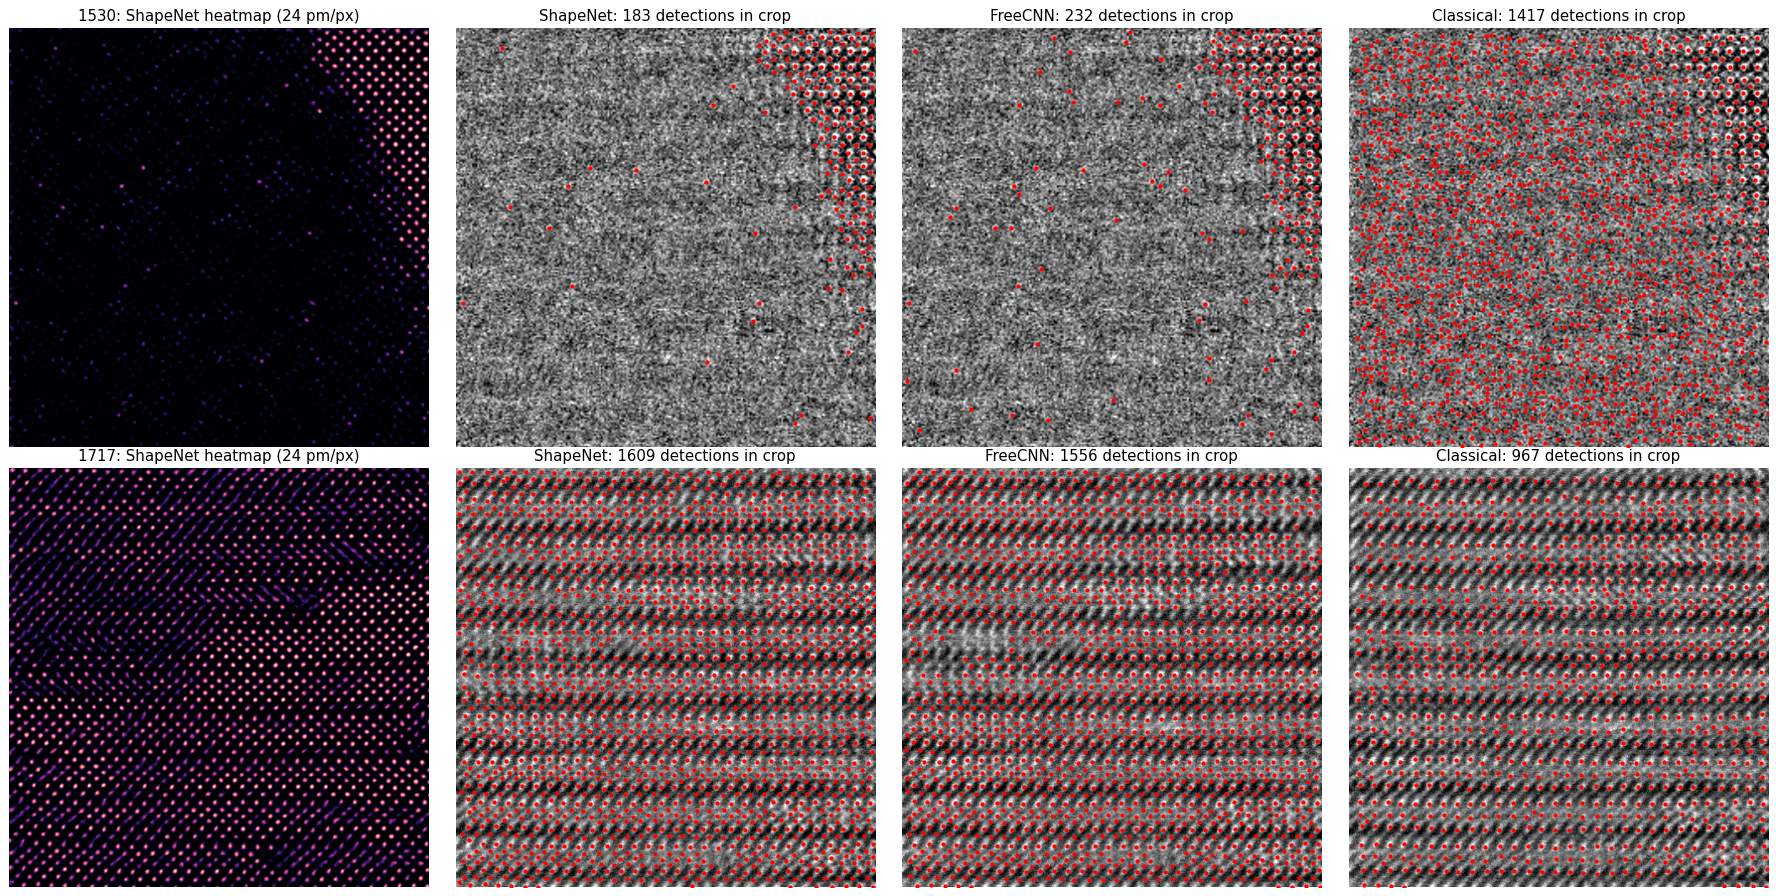

In [ ]:
fig, ax = plt.subplots(2, 4, figsize=(20, 10))
for row, k in enumerate(["1530", "1717"]):
    v, r = frames[k], results[k]; S = 500
    pre = v["pre"][:S, :S]; lo, hi = np.percentile(pre, [0.5, 99.5])
    ax[row, 0].imshow(r["heat"][:S, :S], cmap="magma"); ax[row, 0].set_title(f"{k}: ShapeNet heatmap (24 pm/px)")
    for j, (key, name) in enumerate([("pk", "ShapeNet"), ("pk_free", "FreeCNN"), ("pk_cls", "Classical")]):
        p = r[key]; m = (p[:, 0] < S) & (p[:, 1] < S)
        ax[row, j + 1].imshow(pre, cmap="gray", vmin=lo, vmax=hi); ax[row, j + 1].scatter(p[m, 1], p[m, 0], s=6, c="r")
        ax[row, j + 1].set_title(f"{name}: {m.sum()} detections in crop")
for a in ax.flat: a.axis("off")
plt.tight_layout(); plt.show()

## 11. Quantitative checks on real data (no ground truth)
1. **Agreement on 1644** between ShapeNet and the classical finder, which is reliable on this clean frame (bright columns).
2. **Lattice consistency** (no ground truth needed): the dominant neighbour vectors of each frame are taken from the classical detections (a 2D histogram of neighbour offsets). A detection counts as lattice-consistent if at least two of its neighbours sit on those vectors within 2.5 px (60 pm). Real columns score near 1; random points score about 0.1 to 0.2. The score therefore penalizes detections on noise, double detections and missed neighbours.
3. **Nearest-neighbour histograms**: a lattice-following detector gives sharp peaks at the lattice distances.

1644 ShapeNet (bright class) vs classical: agreement precision 0.980, recall 0.659, F1 0.788

lattice consistency (fraction of detections on the frame's own lattice):
 frame  pm/px |  ShapeNet   FreeCNN Classical  random | n ShapeNet n Classical
  1114   33.7 |     1.000     1.000     0.997   0.273 |      58370       41376
  1115   33.7 |     0.998     0.999     0.985   0.262 |      56518       41651
  1117   16.9 |     1.000     1.000     0.999   0.270 |      14602       11835
  1122   11.9 |     1.000     1.000     0.995   0.274 |       7275        5225
  1245   16.9 |     0.999     0.999     0.989   0.266 |      14348        9705
  1333   16.9 |     0.976     0.974     0.861   0.229 |      13057        8287
  1338   16.9 |     0.964     0.959     0.874   0.226 |      12999        7918
  1520   23.9 |     0.966     0.970     0.896   0.217 |      25238       15968
  1530   47.7 |     0.998     0.997     0.949   0.260 |     111280       84971
  1547   33.7 |     0.999     0.999     0.9

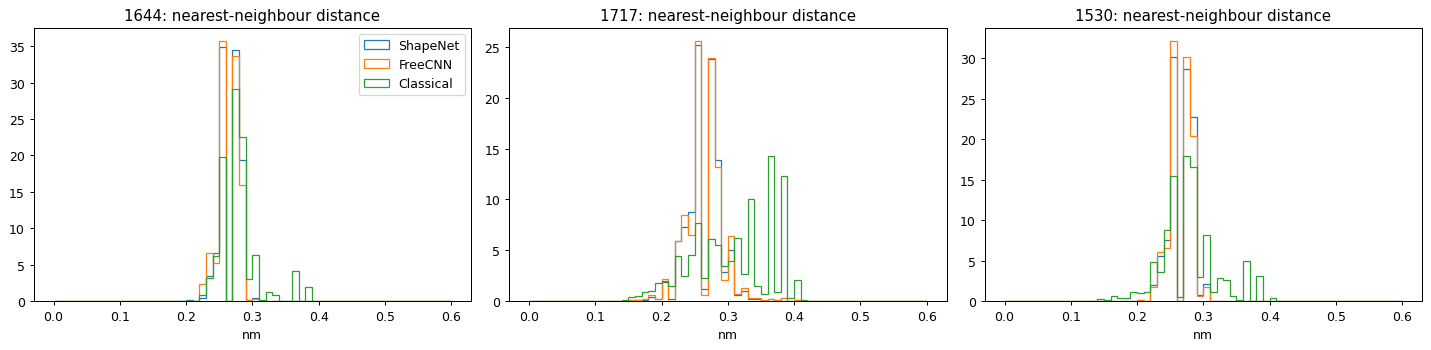

In [ ]:
r = results["1644"]; tp, fp, fn = match(r["pk"][~r["dim"]], r["pk_cls"], r=3)
p_, r_, f_ = prf(tp, fp, fn)
print(f"1644 ShapeNet (bright class) vs classical: agreement precision {p_:.3f}, recall {r_:.3f}, F1 {f_:.3f}")

def frame_lattice_vectors(p, rmax=30, npk=8):
    """Dominant neighbour vectors of a point set (2D histogram of neighbour offsets)."""
    _, ii = cKDTree(p).query(p, k=7)
    v = (p[ii[:, 1:]] - p[:, None, :]).reshape(-1, 2)
    Hh, ye, xe = np.histogram2d(v[:, 0], v[:, 1], bins=2 * rmax + 1, range=[[-rmax - .5, rmax + .5]] * 2)
    Hh = ndi.gaussian_filter(Hh, 1.0); Hh[rmax - 3: rmax + 4, rmax - 3: rmax + 4] = 0
    pk = peak_local_max(Hh, min_distance=4, num_peaks=npk, threshold_rel=0.2)
    return pk.astype(float) - rmax

def lattice_consistency(p, vecs, tol=2.5, need=2):
    """Fraction of detections with >= need neighbours at one of the lattice vectors (within tol px)."""
    if len(p) < 10: return np.nan
    tree = cKDTree(p); ok = np.zeros(len(p), int)
    for v in vecs:
        d, _ = tree.query(p + v); ok += d <= tol
    return float(np.mean(ok >= need))

print(f"\nlattice consistency (fraction of detections on the frame's own lattice):")
print(f"{'frame':>6s} {'pm/px':>6s} | {'ShapeNet':>9s} {'FreeCNN':>9s} {'Classical':>9s} {'random':>7s} | {'n ShapeNet':>10s} {'n Classical':>11s}")
LC = []
rng = np.random.RandomState(0)
for k, v in frames.items():
    R = results[k]; V = frame_lattice_vectors(R["pk_cls"])
    rand = rng.uniform(0, v["pre"].shape[0], (len(R["pk"]), 2))
    vals = [lattice_consistency(R[key], V) for key in ["pk", "pk_free", "pk_cls"]] + [lattice_consistency(rand, V)]
    LC.append(vals)
    print(f"{k:>6s} {v['ps']:6.1f} | {vals[0]:9.3f} {vals[1]:9.3f} {vals[2]:9.3f} {vals[3]:7.3f} | {len(R['pk']):10d} {len(R['pk_cls']):11d}")
LC = np.array(LC)
print(f"{'mean':>6s} {'':6s} | {LC[:,0].mean():9.3f} {LC[:,1].mean():9.3f} {LC[:,2].mean():9.3f} {LC[:,3].mean():7.3f}")

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for j, k in enumerate(["1644", "1717", "1530"]):
    for key, name in [("pk", "ShapeNet"), ("pk_free", "FreeCNN"), ("pk_cls", "Classical")]:
        p = results[k][key]; d = cKDTree(p).query(p, k=2)[0][:, 1] * TARGET_PM / 1000
        ax[j].hist(d, bins=np.linspace(0, 0.6, 61), histtype="step", lw=1.5, label=name, density=True)
    ax[j].set_title(f"{k}: nearest-neighbour distance"); ax[j].set_xlabel("nm")
ax[0].legend(); plt.tight_layout(); plt.show()

## 12. Export coordinates
One CSV per frame in `results/`: original-pixel coordinates (row, col), position in nm, and sublattice class. In Colab, download them from the file browser or copy them to Drive.

In [ ]:
os.makedirs("results", exist_ok=True)
for k, v in frames.items():
    r = results[k]; pts = r["pk"] / v["zoom"]
    arr = np.column_stack([pts, pts * v["ps"] / 1000, r["dim"].astype(int)])
    np.savetxt(f"results/{v['name']}_columns.csv", arr, delimiter=",", fmt=["%.2f", "%.2f", "%.4f", "%.4f", "%d"],
               header="row_px,col_px,y_nm,x_nm,is_dim_sublattice", comments="")
print(sorted(os.listdir("results"))[:5], "...", len(os.listdir("results")), "files")
print(open(f"results/{frames['1644']['name']}_columns.csv").read()[:300])

['1114 STEM 1.45 Mx HAADF_columns.csv', '1115 STEM 1.45 Mx HAADF_columns.csv', '1117 STEM 2.90 Mx HAADF_columns.csv', '1122 STEM 4.10 Mx HAADF_columns.csv', '1245 HAADF 2.90 Mx STEM_columns.csv'] ... 18 files
row_px,col_px,y_nm,x_nm,is_dim_sublattice
289.75,1478.91,3.4560,17.6400,0
877.28,686.13,10.4640,8.1840,1
478.88,122.74,5.7120,1.4640,1
1094.59,1064.41,13.0560,12.6960,0
1782.74,468.82,21.2640,5.5920,1
1384.34,140.85,16.5120,1.6800,1
478.88,156.95,5.7120,1.8720,1
181.09,197.19,2.1600,2.3520,1
275.66,
